# 1. Introduction & Objectifs

Ce notebook construit et évalue un système RAG (Retrieval-Augmented Generation) branché sur la documentation officielle de Python 3.14 : un agent (Ollama, `qwen2.5:7b`) qui interroge une base vectorielle avant de répondre.

Objectifs :
- comparer plusieurs stratégies de chunking et modèles d'embedding, avec des métriques de retrieval (Recall@k, MRR, latence) ;
- évaluer l'agent de bout en bout sur un jeu de questions, y compris des questions hors périmètre ;
- proposer une interface de chat.

La logique lourde (chargement du corpus, chunking, indexation, agent, métriques) est dans `pipeline.py` et `eval.py`. Ce notebook exécute et visualise.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from config import CORPUS_DIR, CHROMA_PERSIST_DIR
from pipeline import (
    load_documents, build_chunking_strategies, add_semantic_chunker, EMBEDDING_MODELS,
    build_default_index, build_agent, chat_history_to_pairs, cached_split,
)
from eval import golden_set, evaluate_retrieval, run_comparison, evaluate_agent_e2e

# 2. Préparation du Corpus

In [2]:
documents = load_documents(CORPUS_DIR)
print(f"{len(documents)} documents chargés")

538 documents chargés


## Chunking

In [3]:
import time

chunking_strategies = build_chunking_strategies()

results = {}
for name, splitter in chunking_strategies.items():
    start = time.time()
    chunks = cached_split(name, splitter, documents)
    results[name] = {
        "Nombre de chunks": len(chunks),
        "Longueur moyenne (car.)": int(sum(len(c.page_content) for c in chunks) / len(chunks)),
        "Temps d'exécution (s)": round(time.time() - start, 4)
    }

df_results = pd.DataFrame.from_dict(results, orient="index")

print("\n--- COMPARATIF DES STRATÉGIES DE CHUNKING ---")
print(df_results.to_string())


--- COMPARATIF DES STRATÉGIES DE CHUNKING ---
             Nombre de chunks  Longueur moyenne (car.)  Temps d'exécution (s)
small_500               38638                      384                 1.8338
medium_1000             17824                      850                 0.8837
token_based             10594                     1539                 0.1148


Stratégie small_500:

    - Volume : Nombre de chunks le plus élevé et taille moyenne la plus faible.

    - Objectif : Recherche d'une haute précision sémantique.

    - Cas d'usage : Idéal pour cibler des détails et répondre à des questions techniques pointues grâce à une forte sensibilité aux micro-informations.

Stratégie medium_1000

    - Volume : Bon compromis/équilibre entre le nombre de chunks et leur taille moyenne.

    - Performance : Se révèle être l'approche la plus rapide à l'exécution.

    - Cas d'usage : Polyvalent, bon équilibre entre préservation du contexte et précision.

Stratégie token_based

    - Fonctionnement : Découpage basé directement sur les unités de tokens lues par les LLM (et non sur les caractères bruts).

    - Avantages : Maîtrise rigoureuse de la taille des segments pour respecter les limites techniques des modèles et optimiser les coûts des API.

    - Limites : Moins respectueuse de la structure textuelle naturelle (sauts de paragraphe) contrairement au découpeur récursif.


# 3. Expérimentations RAG

## Embeddings et indexation

In [4]:
vectorstore, embeddings, chunks = build_default_index(documents, chunking_strategies)


resultats = vectorstore.similarity_search("ceci est une question de test", k=3)
for r in resultats:
    print(r.page_content[:200], "\n---")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1496.13it/s]


    else:
      ...         continue
      ...
      ... """), indent=4))
      Module(
          body=[
              For(
                  target=Name(id='a', ctx=Store()),
                  iter=N 
---
    |
+----------------------------------+-----------------------------------------------+
| "%i"                             | "[-+]?(0[xX][\dA-Fa-f]+|0[0-7]*|\d+)"         |
+----------------------- 
---
, EXTRA)) }
       | invalid_except_star_stmt
   finally_block[asdl_stmt_seq*]:
       | invalid_finally_stmt
       | 'finally' &&':' a=block { a }

   # Match statement
   # ---------------

   matc 
---


les chunks sont récupérés par le modèle d'embedding (réseau de neurone), ce dernier les transforme en listes de tokens, construit un vocabulaire (ici déjà construit lors de l'entraînement du modèle) et remplace les séquences de tokens en séquences d'ids (ceux des tokens dans le vocabulaire). ces séquences sont ensuite passées au réseau de neurone qui les vectorise.

ces vecteurs sont ensuite stockés dans la base de donnée vectorielle (ici ChromaDB).

Le modèle ne lit qu'une fenêtre limitée (256 tokens pour MiniLM, 384 pour mpnet, 512 pour bge-small, ces chiffres représentent la taille de la couche d'entrée du modèle d'embedding) et **ignore silencieusement le reste** d'un chunk trop long ; et Chroma renvoie par défaut une distance L2, la collection est donc configurée en cosinus (`similarité = 1 - distance`).

## Agent RAG

rag_search effectue une recherche de similarité dans note base de donnée, il vectorise d'abord la requête par la même procédé que précédemment puis construit un classement de similarité avec les chunks déjà connus notamment en calculant la similarité grâce à la similarité cosinus.

In [5]:
llm, run_agent = build_agent(vectorstore)

In [6]:
if __name__ == "__main__":
    question = "Comment fonctionne une liste compréhension en Python ?"
    reponse = run_agent(question)
    print("\n--- Réponse finale ---")
    print(reponse)

[Agent] Appel de l'outil: rag_search avec query='python list comprehension syntax and functionality'

--- Réponse finale ---
Une liste compréhension en Python est une manière concise et puissante de créer une nouvelle liste en appliquant une expression à chaque élément d'une ou plusieurs séquences. La structure générale d'une liste compréhension est la suivante :

```python
[expression for expr in sequence1
            for expr2 in sequence2 ...
            for exprN in sequenceN
            if condition]
```

- **Expression** : C'est l'expression qui sera évaluée pour chaque élément de la séquence.
- **For clauses** : Ces clauses spécifient les séquences à itérer. Les séquences ne doivent pas nécessairement être de la même longueur, car elles sont itérées séquentiellement, pas en parallèle.
- **If clause** : Cette clause est optionnelle. Si présente, l'expression est évaluée et ajoutée à la liste uniquement si la condition est vraie.

Par exemple, pour créer une liste des carrés des n

# 4. Évaluation & Résultats

Tout d'abord, il est nécessaire afin de pouvoir mesurer les performances de l'agent de mettre en place des métriques telles que:
- Le Recall@k : Évalue la capacité du pipeline à récupérer l'ensemble des fragments de documentation pertinents parmi les $k$ premiers résultats renvoyés, garantissant ainsi qu'aucune information critique (ex: un paramètre de fonction ou une exception spécifique) n'est omise.

- Le MRR (Mean Reciprocal Rank) : Mesure la position du tout premier résultat pertinent dans la liste de recherche. Un MRR élevé est crucial pour s'assurer que la source la plus exacte se trouve en tête de liste, évitant au LLM le phénomène de Lost in the Middle.

- Le score de similarité moyen : Calcule la distance sémantique (cosine similarity) entre la requête de l'utilisateur et les chunks remontés, servant d'indicateur brut sur la pertinence globale de l'alignement vectoriel.

- La latence : Quantifie le temps de réponse du système de retrieval (embedding de la requête + recherche dans Chroma).

- Le nombre de chunks : Suit le volume de fragments indexés et la granularité du découpage (chunking) appliqué à la documentation Python, permettant d'optimiser le compromis entre précision de recherche et consommation de tokens dans le contexte du modèle.

- Le taux de troncature (`tronqués (%)`) : part des chunks dépassant la fenêtre du modèle d'embedding, dont la fin est alors ignorée silencieusement lors du calcul du vecteur.

Ensuite, il nous faudra un jeu de test afin de tester la pertinence des réponses de notre model (`golden_set`, dans `eval.py`) : 20 questions avec réponse dans la doc, et 5 questions hors périmètre (`should_fail`).

In [7]:
print(f"{len(golden_set)} questions ({sum(not q.get('should_fail') for q in golden_set)} normales, "
      f"{sum(bool(q.get('should_fail')) for q in golden_set)} hors périmètre)")

25 questions (20 normales, 5 hors périmètre)


Le recursive Chunking est déjà un outil efficace mais il est possible qu'une même explication soit séparée entre deux paragraphes, coupant ainsi une partie de la réponse attendue.

On va donc tester un Semantic Chunker qui va découper le texte en fonction de son sens (en utilisant les embeddings dès cette première étape), cependant, il est naturel que ce dernier allonge la durée du chunking car il détecte un sens bien plus précis.

In [8]:
chunking_strategies = add_semantic_chunker(chunking_strategies, embeddings)

In [9]:
embedding_models = EMBEDDING_MODELS

## Comparaison des combinaisons chunking × embedding

Chaque combo (chunking + embedding) est évalué de manière isolée : une collection Chroma dédiée est créée pour chaque combinaison (`build_vectorstore`, dans `pipeline.py`), puis supprimée une fois les métriques calculées.

In [10]:
df_experiments = run_comparison(documents, chunking_strategies, embedding_models, golden_set, k=3)
df_experiments.sort_values(by=["Recall@3", "MRR"], ascending=False)

--- Combo: chunking=small_500 | embedding=MiniLM-L6-v2 ---


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1968.71it/s]


--- Combo: chunking=small_500 | embedding=mpnet-base-v2 ---


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 385.79it/s]


--- Combo: chunking=small_500 | embedding=bge-small-en ---


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1126.11it/s]


--- Combo: chunking=medium_1000 | embedding=MiniLM-L6-v2 ---
--- Combo: chunking=medium_1000 | embedding=mpnet-base-v2 ---
--- Combo: chunking=medium_1000 | embedding=bge-small-en ---
--- Combo: chunking=token_based | embedding=MiniLM-L6-v2 ---
--- Combo: chunking=token_based | embedding=mpnet-base-v2 ---
--- Combo: chunking=token_based | embedding=bge-small-en ---
--- Combo: chunking=semantic | embedding=MiniLM-L6-v2 ---
--- Combo: chunking=semantic | embedding=mpnet-base-v2 ---
--- Combo: chunking=semantic | embedding=bge-small-en ---


,chunking,embedding,nb_chunks,longueur_moyenne,temps_chunking (s),temps_indexation (s),tronqués (%),Recall@3,MRR,Score similarité moyen,Latence retrieval moyenne (s)
9,semantic,MiniLM-L6-v2,6245,2326,6126.3668,214.7905,59.7,0.95,0.900,0.4487,0.0321
2,small_500,bge-small-en,38638,384,0.3586,1811.5253,0.0,0.95,0.858,0.7498,0.0342
7,token_based,mpnet-base-v2,10594,1539,5.3174,67108.1058,79.2,0.95,0.858,0.4957,0.0282
1,small_500,mpnet-base-v2,38638,384,0.3586,7226.0505,0.0,0.95,0.842,0.5490,0.0752
3,medium_1000,MiniLM-L6-v2,17824,850,0.1564,386.5022,40.7,0.90,0.875,0.4558,0.0142
11,semantic,bge-small-en,6245,2326,6126.3668,443.3164,41.9,0.90,0.875,0.7245,0.0187
6,token_based,MiniLM-L6-v2,10594,1539,5.3174,460.9781,94.3,0.90,0.842,0.4467,0.0337
5,medium_1000,bge-small-en,17824,850,0.1564,9254.4264,2.9,0.90,0.817,0.7358,0.0667
4,medium_1000,mpnet-base-v2,17824,850,0.1564,5407.8541,5.5,0.90,0.808,0.5204,0.0646
8,token_based,bge-small-en,10594,1539,5.3174,923.7745,16.2,0.90,0.792,0.7272,0.0188


On observe que les trois modèles d'embedding sont globalement proches sur ce jeu de test : bge-small-en et mpnet-base-v2 arrivent à égalité en recall moyen (0.9125), MiniLM-L6-v2 légèrement en dessous (0.90), mais c'est MiniLM-L6-v2 qui obtient le meilleur MRR moyen (0.8585 contre 0.8395 pour mpnet et 0.8355 pour bge). L'écart entre modèles tient en 1 à 2 questions sur les 20 évaluées, ce qui est à la limite du bruit de mesure avec un jeu de test aussi petit.

Le combo qui ressort le mieux sur Recall@3 et MRR combinés est semantic + MiniLM-L6-v2 (0.95 / 0.900), suivi de très près par small_500 + bge-small-en et token_based + mpnet-base-v2 (0.95 / 0.858 chacun). Avec 20 questions, ces écarts représentent littéralement 1 question : ce classement est une indication, pas une hiérarchie fiable.

En pratique, small_500 + bge-small-en est le combo le plus intéressant : il égale presque le meilleur score, avec un chunking quasi instantané (0.36s) et une indexation raisonnable (≈30 min). semantic + MiniLM-L6-v2 obtient le meilleur score mais au prix d'un chunking de ≈1h42 (heureusement mis en cache, donc payé une seule fois).

Le combo token_based + mpnet-base-v2 affiche un temps d'indexation de 67 108s (≈18h36), très largement au-dessus de tous les autres (qui vont de 387s à 9254s). Ces durées excessives s'expliquent notamment par la mise en pause du processus (là où le timer a continué de touner). 

Sur la troncature (`tronqués (%)`) : elle est quasi nulle pour small_500 (chunks de 384 caractères, largement sous la fenêtre de tous les modèles) et reste contenue pour medium_1000 (jusqu'à 40.7% avec MiniLM). Elle explose en revanche pour token_based et semantic, notamment token_based + MiniLM-L6-v2 à 94.3% : la quasi-totalité du contenu de chaque chunk est ignorée par l'embedding. Fait notable : ça ne se traduit pas par un Recall ou un MRR dégradé (token_based + MiniLM reste à 0.90 / 0.842, dans la moyenne haute). Une explication possible : le début du chunk (seule partie réellement vue par le modèle) contient déjà les termes techniques recherchés — reste une hypothèse à vérifier, pas une conclusion, vu la taille du jeu de test.

Le `Score similarité moyen` n'est toujours pas comparable d'un modèle à l'autre : bge-small-en tourne autour de 0.72-0.75, mpnet autour de 0.49-0.55, MiniLM autour de 0.44-0.50. Ce n'est pas que bge trouve de « meilleurs » passages, c'est que son espace vectoriel a une échelle de similarité différente.

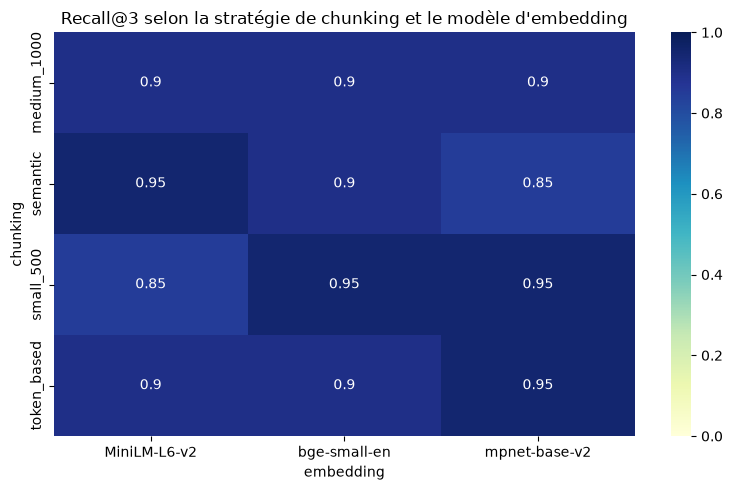

In [11]:
pivot_recall = df_experiments.pivot(index="chunking", columns="embedding", values="Recall@3")

plt.figure(figsize=(8, 5))
sns.heatmap(pivot_recall, annot=True, cmap="YlGnBu", vmin=0, vmax=1)
plt.title("Recall@3 selon la stratégie de chunking et le modèle d'embedding")
plt.tight_layout()
plt.show()

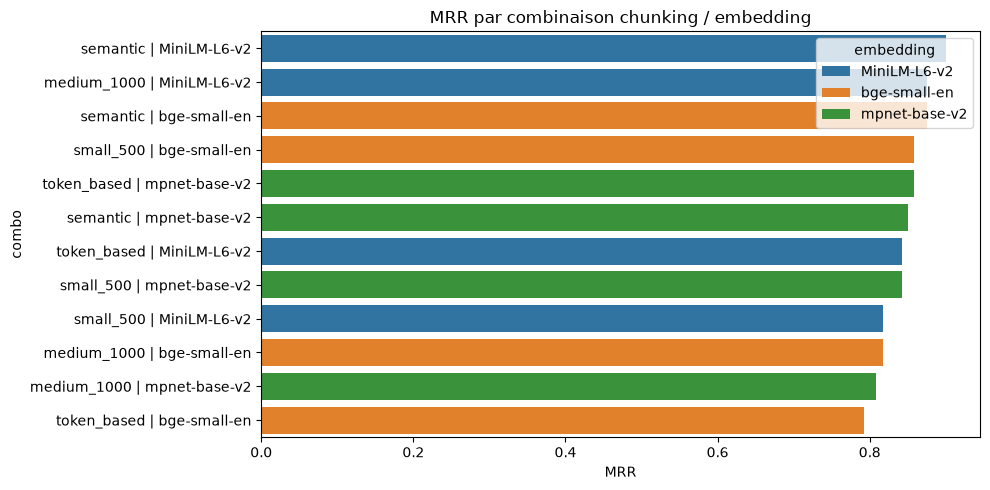

In [12]:
plt.figure(figsize=(10, 5))
df_plot = df_experiments.copy()
df_plot["combo"] = df_plot["chunking"] + " | " + df_plot["embedding"]
sns.barplot(data=df_plot.sort_values("MRR", ascending=False), x="MRR", y="combo", hue="embedding", dodge=False)
plt.title("MRR par combinaison chunking / embedding")
plt.tight_layout()
plt.show()

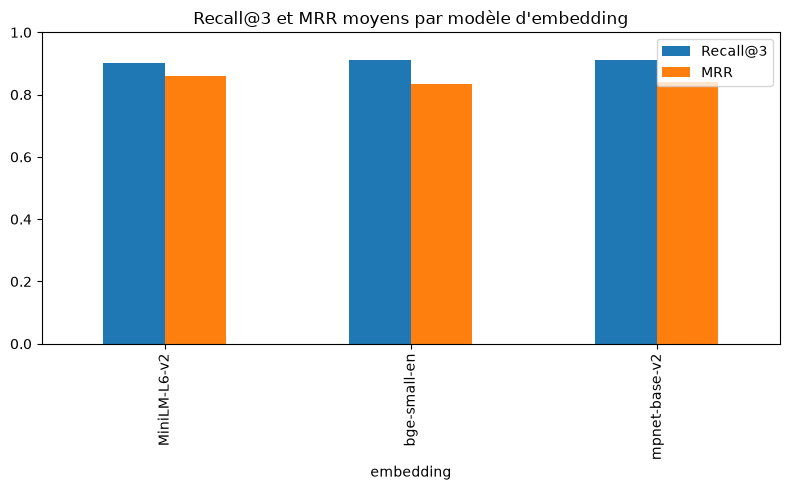

In [13]:
plt.figure(figsize=(8, 5))
df_experiments.groupby("embedding")[["Recall@3", "MRR"]].mean().plot(kind="bar", ax=plt.gca())
plt.title("Recall@3 et MRR moyens par modèle d'embedding")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

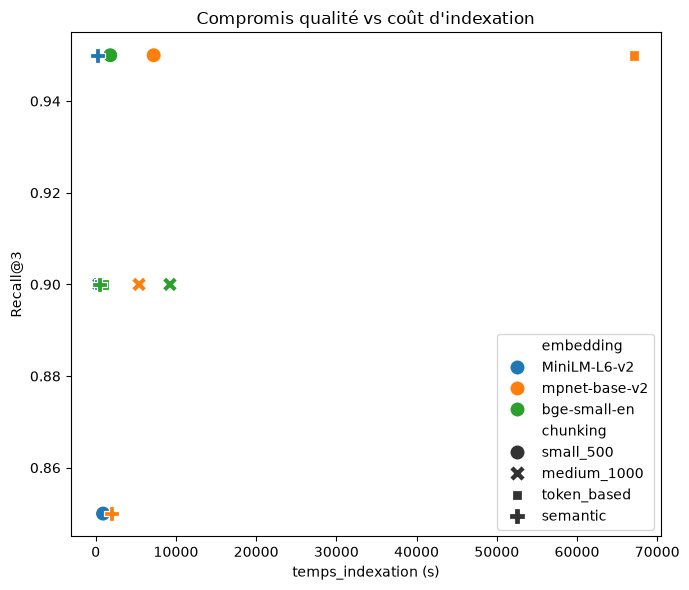

In [14]:
plt.figure(figsize=(7, 6))
sns.scatterplot(
    data=df_experiments, x="temps_indexation (s)", y="Recall@3",
    hue="embedding", style="chunking", s=120
)
plt.title("Compromis qualité vs coût d'indexation")
plt.tight_layout()
plt.show()

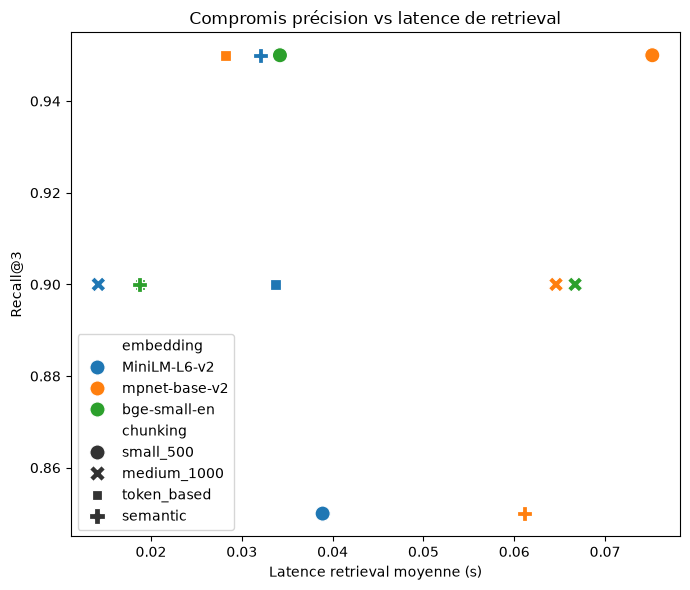

In [15]:
plt.figure(figsize=(7, 6))
sns.scatterplot(
    data=df_experiments, x="Latence retrieval moyenne (s)", y="Recall@3",
    hue="embedding", style="chunking", s=120
)
plt.title("Compromis précision vs latence de retrieval")
plt.tight_layout()
plt.show()

## Évaluation de bout en bout

In [16]:
df_e2e = evaluate_agent_e2e(golden_set, run_agent, llm)
print(df_e2e.groupby("should_fail")["reponse_pertinente"].mean())   # questions normales vs hors périmètre (refus)
df_e2e

[Agent] Appel de l'outil: rag_search avec query='python list comprehension syntax'
[Agent] Appel de l'outil: rag_search avec query='python default function arguments'
[Agent] Appel de l'outil: rag_search avec query='difference between list and tuple in python'
[Agent] Appel de l'outil: rag_search avec query='python try except documentation'
[Agent] Appel de l'outil: rag_search avec query='how to open and read a file in python'
[Agent] Appel de l'outil: rag_search avec query='itertools.groupby usage'
[Agent] Appel de l'outil: rag_search avec query='python pathlib how to manipulate file paths'
[Agent] Appel de l'outil: rag_search avec query='python json serialize deserialize'
[Agent] Appel de l'outil: rag_search avec query='creating a generator function with yield in python'
[Agent] Appel de l'outil: rag_search avec query='python merge dictionaries'
[Agent] Appel de l'outil: rag_search avec query='python lambda function example usage'
[Agent] Appel de l'outil: rag_search avec query='iter

,question,should_fail,latence_totale (s),reponse_pertinente,longueur_reponse
0,Comment fonctionne une liste en compréhension ...,False,61.88,0,1847
1,Comment définir une fonction avec des argument...,False,44.13,1,1978
2,Quelle est la différence entre une liste et un...,False,48.49,0,2196
3,Comment gérer les exceptions avec try/except ?,False,43.03,1,2195
4,Comment ouvrir et lire un fichier en Python ?,False,34.10,1,1463
5,Comment utiliser itertools.groupby pour groupe...,False,51.09,1,1912
6,Comment manipuler des chemins de fichiers avec...,False,48.85,0,1797
7,Comment sérialiser et désérialiser du JSON en ...,False,35.83,1,1853
8,Comment créer une fonction génératrice avec yi...,False,42.44,0,2017
9,Comment fusionner deux dictionnaires avec l'op...,False,38.46,1,1240


Sur les 20 questions normales, 14 réponses contiennent les mots-clés attendus (70%). Sur les 5 questions hors périmètre, seules 2 ont été correctement refusées (40%) : les questions 20 (tarte aux pommes) et 23 (`print_colorful`) sont bien identifiées comme hors sujet / inexistantes, mais l'agent répond comme si elles existaient pour les questions 21 (`quantum_compute`), 22 (serveur web `py_express`) et 24 (smart contract Solidity) — malgré la consigne du prompt système de ne jamais inventer de module ou de fonction.

La question 16 (type hints) est un cas à part : 2696s de latence et 182 360 caractères de réponse, très loin des autres (25 à 78s, 1000 à 4000 caractères). Ça ressemble à une génération qui s'est emballée (boucle de répétition côté modèle) plutôt qu'à une vraie réponse longue. Ajouter une limite de longueur de génération (`num_predict` côté Ollama) éviterait qu'un cas comme celui-ci fasse exploser la latence moyenne et le coût.

Note : `reponse_pertinente` reste une mesure approximative par mots-clés, elle indique une tendance, pas un score de qualité précis.

# 5. Conclusion & Pistes d'amélioration

Sur ce jeu de test (20 questions normales + 5 hors périmètre), les trois modèles d'embedding sont proches : bge-small-en et mpnet-base-v2 sont ex-aequo sur le recall moyen (0.9125), MiniLM-L6-v2 est légèrement en retrait (0.90) mais obtient le meilleur MRR moyen (0.8585). Aucun modèle ne domine franchement les autres, et les écarts entre combos (souvent 1 question sur 20) sont trop faibles pour être considérés comme significatifs.

Le combo actuellement utilisé par défaut (`token_based` + `bge-small-en`, dans `pipeline.py`) n'est pas le mieux classé ici (Recall@3 0.90, MRR 0.792, le MRR le plus faible de tous les combos bge). `small_500` + `bge-small-en` ou `semantic` + `MiniLM-L6-v2` seraient de meilleurs choix par défaut sur ces résultats.

Côté agent, 70% des questions normales obtiennent une réponse contenant les mots-clés attendus, mais seules 40% des questions hors périmètre sont correctement refusées : l'agent invente sur 3 des 5 questions pièges (`quantum_compute`, `py_express`, Solidity), malgré la consigne de ne jamais inventer.

Pistes d'amélioration :
- Changer la combinaison par défaut pour `small_500` + `bge-small-en` (meilleur compromis coût/qualité sur ces résultats) ou `semantic` + `MiniLM-L6-v2` (meilleur score brut, chunking coûteux mais mis en cache).
- Plafonner la longueur de génération de l'agent (`num_predict`), pour éviter des cas comme la question 16 (2696s, 182 360 caractères).
- Renforcer le refus sur les questions hors périmètre : seuil de similarité minimale avant d'appeler le LLM, ou reformulation plus stricte du prompt système.
- Élargir le jeu de test golden_set au-delà de 20 questions : à cet effectif, un écart de recall de 0.05 représente une seule question.
- Ajouter une recherche hybride (BM25 + vecteurs) ou un reranker, cités dans les métriques mais non implémentés.

# Interface de chat

Petite interface Gradio au-dessus de `run_agent` (avec l'historique de la conversation). Elle utilise l'index `vectorstore` construit en section 3.

In [17]:
import gradio as gr

def chat(message, history):
    return run_agent(message, history=chat_history_to_pairs(history)[-6:])   # on garde les 6 derniers échanges

demo = gr.ChatInterface(
    chat,
    title="Assistant documentation Python",
    description="Réponses fondées sur la documentation officielle de Python 3.14 (RAG local avec Ollama).",
    examples=["Comment fonctionne une liste en compréhension ?", "Comment lire et écrire du JSON ?"],
)
demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


[Agent] Appel de l'outil: rag_search avec query='python list comprehension syntax'
